In [1]:
import os
import cv2
import argparse
from ultralytics  import YOLO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from analyze_errors.matching import match_gt_with_results
from analyze_errors.metrics_calculate import compute_map, box_metrics_calculate, frame_level_metrics, compute_map_coco_style
from analyze_errors.visualization import visualize_prediction
from analyze_errors.eigen_cam import EigenCAM, visualize_prediction_with_cam, only_eigencam_visualizate

# === parameters ===
RANDOM_STATE = 42

In [2]:
# === parameters ===
path2data_file = "./data_v2.yaml"
split = "val"
path2model = "runs/detect/baseline_n_v0/non_aug_detect/weights/best.pt"
path2model_v1 = "runs/detect/baseline_n_v1/aug_clahe/weights/best.pt"
path2model_v2 = "runs/detect/baseline_n_v2/aug_frangi/weights/best.pt"
imgsize = 512
project = "baseline_v0"
exp_name = "errors_analyze_overfitting_clahe"
conf = 0.001

nms_iou = 0.6
match_iou = 0.5

batch_size = 32

In [181]:
# === model init ===
model = YOLO(path2model_v2)

In [185]:
source_baseline_v0 = "./dataset_yolo/val_fold_1_s.txt"
source_baseline_v1 = "./dataset_v1/val_fold_1_s.txt"
source_baseline_v2 = "./dataset_v2/val_fold_1.txt"

results = model.predict(
    source=source_baseline_v2,
    imgsz=imgsize,
    batch=batch_size,
    workers=2,
    seed=RANDOM_STATE,
    deterministic=True,
    conf=conf, # 0.0001 # низкий порог для честного расчёта mAP
    iou=nms_iou, # IoU для NMS при валидации
    verbose=False # Отключить печать
)

In [186]:
eigencam = EigenCAM(model, target_layer_idx=15)   # P5; для мелких объектов попробуй 15 (P3)

### mAP calculate

In [187]:
m = compute_map(results, "./dataset_v2/labels", num_classes=1)
print(f"mAP0.5: {m['map_05']:0.4f}")
print(f"mAP0.5-0.95: {m['map_50_95']:.4f}")
print(m)

mAP0.5: 0.1800
mAP0.5-0.95: 0.0595
{'ap_table': array([[    0.18004,     0.13978,     0.10776,    0.074312,    0.044884,    0.031962,    0.012911,   0.0022103,  0.00090011,           0]]), 'map_05': 0.1800437761114879, 'map_50_95': 0.05947682590897999, 'per_iou_map': {0.5: 0.1800437761114879, 0.55: 0.13977950660602576, 0.6000000000000001: 0.10776462376400069, 0.6500000000000001: 0.07431201101286608, 0.7000000000000002: 0.044884346201466356, 0.7500000000000002: 0.03196213455563043, 0.8000000000000003: 0.012911496149529423, 0.8500000000000003: 0.0022102527570128042, 0.9000000000000004: 0.0009001119317805252, 0.9500000000000004: 0.0}, 'per_class_ap_05': {0: 0.1800437761114879}}


In [188]:
coco_m = compute_map_coco_style(results, "./dataset_v2/labels", num_classes=1)
print(f"mAP0.5: {coco_m['map_05']}")
print(f"mAP0.5-0.95: {coco_m['map_50_95']}")
print(coco_m)

mAP0.5: 0.18170838057994843
mAP0.5-0.95: 0.05971655994653702
{'ap_table': array([[    0.18171,     0.14035,     0.10782,    0.074389,    0.044884,    0.031962,    0.012911,   0.0022234,  0.00091327,           0]], dtype=float32), 'map_05': 0.18170838057994843, 'map_50_95': 0.05971655994653702, 'per_iou_map': {0.5: 0.18170838057994843, 0.550000011920929: 0.1403496116399765, 0.6000000238418579: 0.10782396048307419, 0.6499999761581421: 0.07438892126083374, 0.699999988079071: 0.044884346425533295, 0.75: 0.031962133944034576, 0.800000011920929: 0.012911495752632618, 0.8500000238418579: 0.0022234106436371803, 0.8999999761581421: 0.0009132698178291321, 0.949999988079071: 0.0}, 'per_class_ap_05': {0: 0.18170838057994843}, 'gt_count': array([1189])}


In [189]:
frame_m = frame_level_metrics(results, "./dataset_v2/labels")
for item in frame_m:
    print(f"{item}: {frame_m[item]:.4f}")

sensitivity: 0.3561
specificity: 0.9330
precision: 0.8969
recall: 0.3561
f1: 0.5098
accuracy: 0.5748
tp: 235.0000
fp: 27.0000
fn: 425.0000
tn: 376.0000


### TP, FP, FN, Precision, Recall for GT

In [190]:
boxes_metrics = []
for c in np.linspace(0.05, 0.9, 18):
    m = box_metrics_calculate(results, "./dataset_yolo/labels", iou=match_iou, conf=c)
    boxes_metrics.append({
        "conf": c,
        "iou": match_iou,
        "metrics": m 
    })

In [191]:
for item in boxes_metrics:
    ii = item['metrics']
    print(f"conf: {item['conf']:.2f}, | TP: {ii['TP']} | FP: {ii['FP']} | FN: {ii['FN']} | P: {ii['P']:.4f} R: {ii['R']:.4f} | F1: {ii['F1']:.4f}")

conf: 0.05, | TP: 202 | FP: 430 | FN: 987 | P: 0.3196 R: 0.1699 | F1: 0.2219
conf: 0.10, | TP: 182 | FP: 323 | FN: 1007 | P: 0.3604 R: 0.1531 | F1: 0.2149
conf: 0.15, | TP: 166 | FP: 249 | FN: 1023 | P: 0.4000 R: 0.1396 | F1: 0.2070
conf: 0.20, | TP: 151 | FP: 196 | FN: 1038 | P: 0.4352 R: 0.1270 | F1: 0.1966
conf: 0.25, | TP: 142 | FP: 164 | FN: 1047 | P: 0.4641 R: 0.1194 | F1: 0.1900
conf: 0.30, | TP: 128 | FP: 144 | FN: 1061 | P: 0.4706 R: 0.1077 | F1: 0.1752
conf: 0.35, | TP: 120 | FP: 125 | FN: 1069 | P: 0.4898 R: 0.1009 | F1: 0.1674
conf: 0.40, | TP: 114 | FP: 114 | FN: 1075 | P: 0.5000 R: 0.0959 | F1: 0.1609
conf: 0.45, | TP: 104 | FP: 87 | FN: 1085 | P: 0.5445 R: 0.0875 | F1: 0.1507
conf: 0.50, | TP: 100 | FP: 64 | FN: 1089 | P: 0.6098 R: 0.0841 | F1: 0.1478
conf: 0.55, | TP: 85 | FP: 46 | FN: 1104 | P: 0.6489 R: 0.0715 | F1: 0.1288
conf: 0.60, | TP: 74 | FP: 29 | FN: 1115 | P: 0.7184 R: 0.0622 | F1: 0.1146
conf: 0.65, | TP: 59 | FP: 16 | FN: 1130 | P: 0.7867 R: 0.0496 | F1: 0.

### Visualization

In [204]:
# 40, 50, 1200, 950, 770
result_item = results[770]
stem = result_item.path.split("\\")[-1].split('.')[0]
print(stem)
path2label = f"./dataset_v2/labels/{stem}.txt"

# un_gt - idx для FN (из GT) - то есть можно сопоставить с теми, которые не были найдены
matches, un_gt, un_pred, gt = match_gt_with_results(
    result_item, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

p40_v11_00025


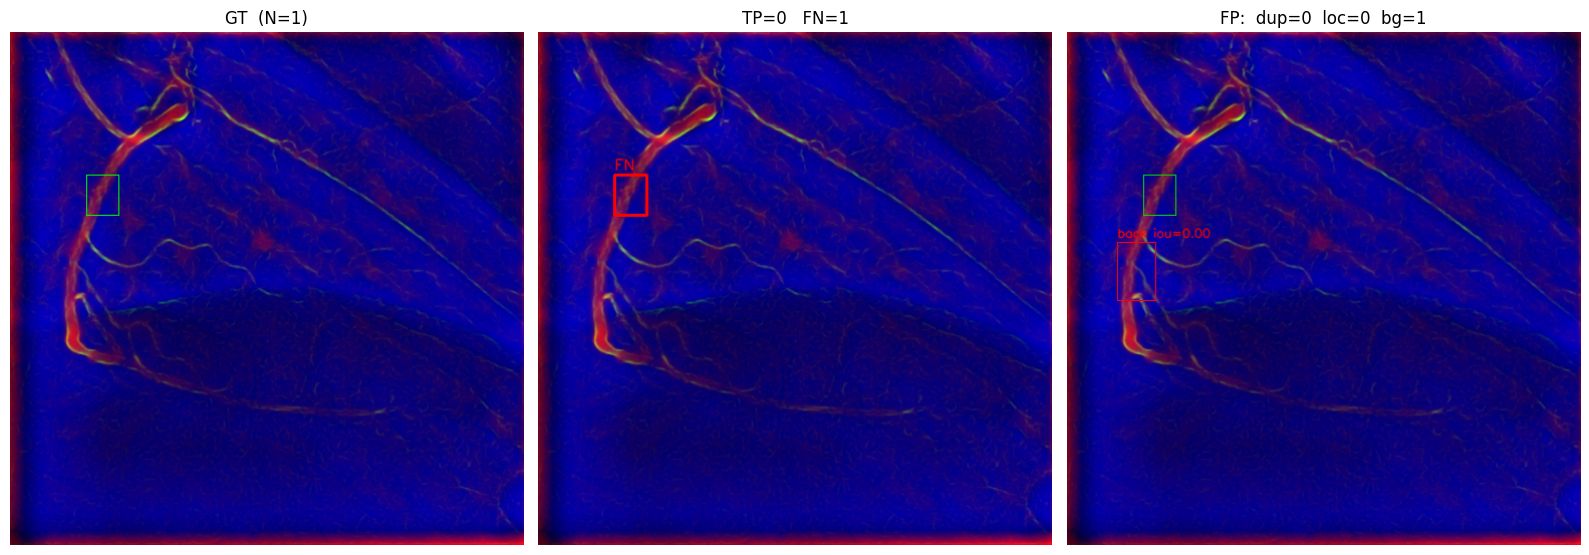

In [205]:
visualize_prediction(
    result_item, matches, un_gt, un_pred, gt
)

### EigenCAM visualization

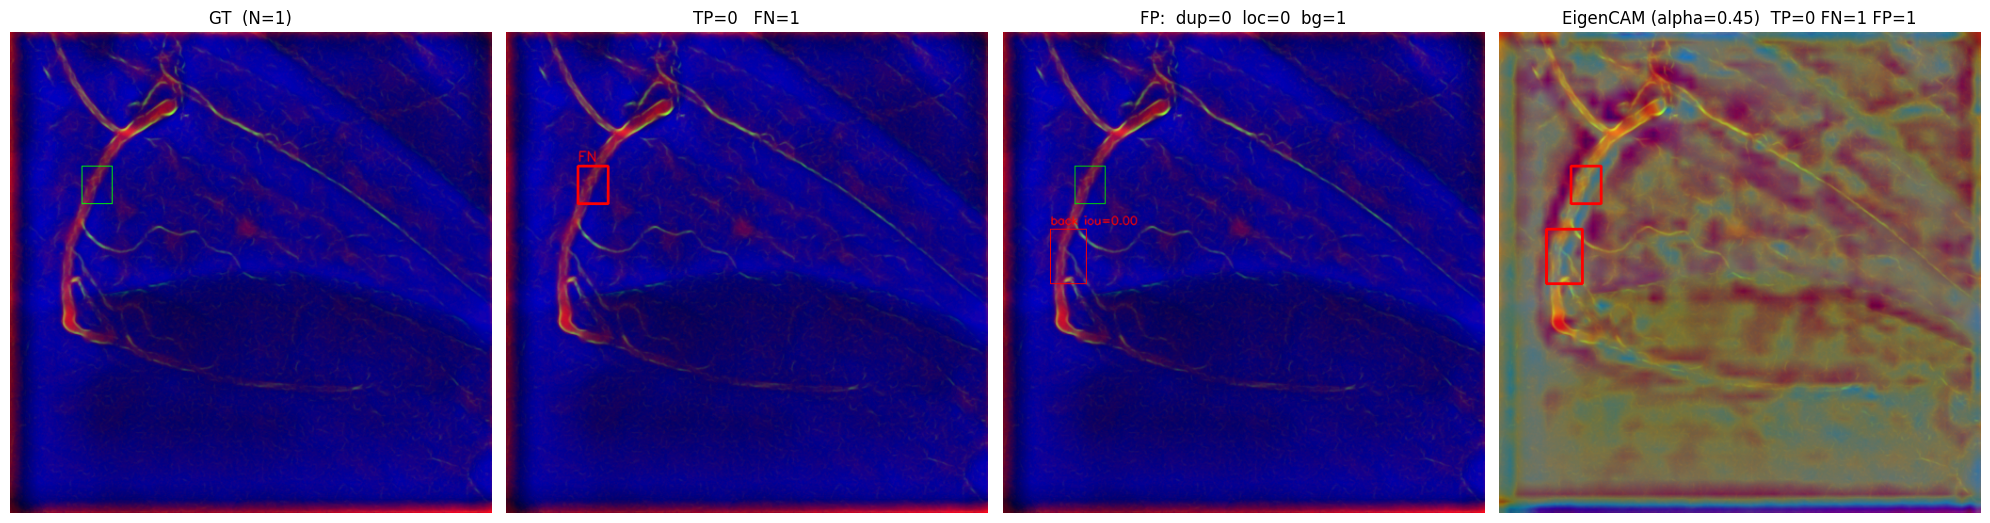

In [206]:
result_cam, heatmap, feat_shape = eigencam(result_item.path, imgsz=imgsize)

matches, un_gt, un_pred, gt = match_gt_with_results(
    result_cam, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

visualize_prediction_with_cam(result_cam, matches, un_gt, un_pred, gt, heatmap, alpha=0.45, figsize=(20, 15))

In [207]:
img_path = f"./dataset_yolo/images/{stem}.png"
img_i = cv2.imread(img_path)
img_i = cv2.cvtColor(img_i, cv2.COLOR_BGR2RGB)

result_cam.orig_img = img_i

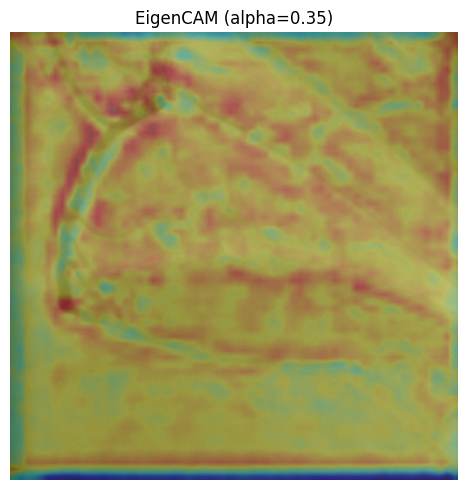

In [208]:
only_eigencam_visualizate(result_cam, heatmap, alpha=0.35, figsize=(9, 5))